#### Dependencias

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
from scipy.stats import kstest

#### Parámetros

In [ ]:
SEED = 42 #para que salgan siempre iguales al ejecutar las notebook

#### Lectura e integridad

In [ ]:
df = pd.read_csv("ai_student_impact_dataset.csv")

In [ ]:
df.head ()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium


In [ ]:
df.tail ()

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
49995,149996,Business,Senior,2.899,12.16,Copywriting/Drafting,Beginner,2,False,13.36,2,Allowed_With_Citation,2,3.584,66.16,High
49996,149997,STEM,Senior,2.870,2.51,Copywriting/Drafting,Intermediate,1,False,4.67,3,Actively_Encouraged,3,3.096,81.62,Medium
49997,149998,Business,Senior,3.177,15.87,Summarizing_Reading,Advanced,5,True,3.92,4,Allowed_With_Citation,5,3.605,97.21,High
49998,149999,Business,Junior,3.398,19.91,Debugging/Troubleshooting,Intermediate,5,False,7.10,5,Allowed_With_Citation,3,3.527,84.12,Medium
49999,150000,Arts,Sophomore,3.242,3.30,Copywriting/Drafting,Beginner,1,False,3.93,2,Allowed_With_Citation,6,3.261,76.16,Low


In [ ]:
df.sample(10, random_state=SEED)

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
33553,133554,STEM,Graduate,2.208,1.75,Direct_Answer_Generation,Intermediate,1,True,8.22,2,Actively_Encouraged,2,2.582,64.42,Low
9427,109428,Arts,Graduate,2.931,3.08,Ideation,Beginner,3,True,11.68,5,Actively_Encouraged,8,3.452,82.34,Low
199,100200,Arts,Sophomore,2.874,14.28,Direct_Answer_Generation,Advanced,3,False,13.68,6,Strict_Ban,5,3.035,87.08,High
12447,112448,Medical,Junior,2.517,7.42,Copywriting/Drafting,Beginner,1,True,1.00,1,Allowed_With_Citation,1,2.754,78.94,High
39489,139490,Business,Sophomore,2.927,3.12,Copywriting/Drafting,Intermediate,3,False,5.59,3,Actively_Encouraged,4,3.084,63.73,Low
42724,142725,Business,Freshman,3.830,3.61,Copywriting/Drafting,Beginner,3,True,15.50,2,Allowed_With_Citation,3,3.725,82.04,Low
10822,110823,Medical,Graduate,2.404,3.25,Direct_Answer_Generation,Beginner,1,False,9.16,4,Allowed_With_Citation,2,3.032,56.49,High
49498,149499,Humanities,Freshman,3.385,13.92,Summarizing_Reading,Intermediate,3,False,11.98,4,Allowed_With_Citation,8,3.392,66.91,High
4144,104145,Medical,Senior,3.014,3.24,Ideation,Beginner,2,False,10.18,3,Allowed_With_Citation,4,3.227,90.19,Low
36958,136959,STEM,Freshman,2.847,7.48,Debugging/Troubleshooting,Beginner,1,False,8.40,4,Strict_Ban,3,3.024,67.21,Low


In [ ]:
df.shape

(50000, 16)

In [ ]:
df.info () #cuantos valores nulos tiene el dataset. - No tiene porque las 16 columnas tienen 50000 valores

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 16 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   Student_ID                  50000 non-null  int64  
 1   Major_Category              50000 non-null  str    
 2   Year_of_Study               50000 non-null  str    
 3   Pre_Semester_GPA            50000 non-null  float64
 4   Weekly_GenAI_Hours          50000 non-null  float64
 5   Primary_Use_Case            50000 non-null  str    
 6   Prompt_Engineering_Skill    50000 non-null  str    
 7   Tool_Diversity              50000 non-null  int64  
 8   Paid_Subscription           50000 non-null  bool   
 9   Traditional_Study_Hours     50000 non-null  float64
 10  Perceived_AI_Dependency     50000 non-null  int64  
 11  Institutional_Policy        50000 non-null  str    
 12  Anxiety_Level_During_Exams  50000 non-null  int64  
 13  Post_Semester_GPA           50000 non-null

In [ ]:
df.Student_ID.nunique() #cuantos estudiantes duplicados hay? - No hay estudiantes duplicados.

50000

In [ ]:
df.Major_Category.unique() #cuantos tipos de carreras hay? - Hay 6 tipos de carreras.

<StringArray>
['Humanities', 'Medical', 'Business', 'STEM', 'Arts']
Length: 5, dtype: str

In [ ]:
df.Year_of_Study.unique()# cuantos tipos de años de estudio hay? - Hay 4 tipos de años de estudio.

<StringArray>
['Senior', 'Junior', 'Freshman', 'Sophomore', 'Graduate']
Length: 5, dtype: str

In [ ]:
df.Primary_Use_Case.unique()# cuantos tipos de casos de uso hay? - Hay 5 tipos de casos de uso.

<StringArray>
[     'Copywriting/Drafting',                  'Ideation',
       'Summarizing_Reading', 'Debugging/Troubleshooting',
  'Direct_Answer_Generation']
Length: 5, dtype: str

In [ ]:
df.Prompt_Engineering_Skill.unique() #cuantos tipos de habilidades de ingeniería de prompts hay? - Hay 3 tipos de habilidades de ingeniería de prompts.

<StringArray>
['Beginner', 'Advanced', 'Intermediate']
Length: 3, dtype: str

In [ ]:
df.Institutional_Policy.unique() #cuantos tipos de políticas institucionales hay? - Hay 3 tipos de políticas institucionales.

<StringArray>
['Allowed_With_Citation', 'Strict_Ban', 'Actively_Encouraged']
Length: 3, dtype: str

In [ ]:
df.Burnout_Risk_Level.unique() #cuantos tipos de niveles de riesgo de burnout hay? - Hay 3 tipos de niveles de riesgo de burnout.

<StringArray>
['High', 'Low', 'Medium']
Length: 3, dtype: str

In [ ]:
df.nunique() # cuantos valores únicos hay en cada columna?

Student_ID                    50000
Major_Category                    5
Year_of_Study                     5
Pre_Semester_GPA               2389
Weekly_GenAI_Hours             3566
Primary_Use_Case                  5
Prompt_Engineering_Skill          3
Tool_Diversity                    5
Paid_Subscription                 2
Traditional_Study_Hours        2516
Perceived_AI_Dependency          10
Institutional_Policy              3
Anxiety_Level_During_Exams       10
Post_Semester_GPA              2269
Skill_Retention_Score          5872
Burnout_Risk_Level                3
dtype: int64

In [ ]:
df #vista general del dataset.

,Student_ID,Major_Category,Year_of_Study,Pre_Semester_GPA,Weekly_GenAI_Hours,Primary_Use_Case,Prompt_Engineering_Skill,Tool_Diversity,Paid_Subscription,Traditional_Study_Hours,Perceived_AI_Dependency,Institutional_Policy,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score,Burnout_Risk_Level
0,100001,Humanities,Senior,2.418,23.31,Copywriting/Drafting,Beginner,1,True,8.13,5,Allowed_With_Citation,6,2.393,86.44,High
1,100002,Medical,Junior,3.821,1.12,Ideation,Advanced,5,False,16.65,3,Allowed_With_Citation,9,3.696,69.39,Low
2,100003,Business,Freshman,3.398,21.26,Summarizing_Reading,Beginner,2,False,10.35,5,Strict_Ban,9,3.499,73.93,Medium
3,100004,Business,Senior,3.789,1.82,Copywriting/Drafting,Intermediate,4,False,15.23,2,Allowed_With_Citation,2,4.000,63.58,Medium
4,100005,STEM,Sophomore,3.635,9.29,Debugging/Troubleshooting,Advanced,4,False,12.55,4,Allowed_With_Citation,4,3.798,100.00,Medium
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49995,149996,Business,Senior,2.899,12.16,Copywriting/Drafting,Beginner,2,False,13.36,2,Allowed_With_Citation,2,3.584,66.16,High
49996,149997,STEM,Senior,2.870,2.51,Copywriting/Drafting,Intermediate,1,False,4.67,3,Actively_Encouraged,3,3.096,81.62,Medium
49997,149998,Business,Senior,3.177,15.87,Summarizing_Reading,Advanced,5,True,3.92,4,Allowed_With_Citation,5,3.605,97.21,High
49998,149999,Business,Junior,3.398,19.91,Debugging/Troubleshooting,Intermediate,5,False,7.10,5,Allowed_With_Citation,3,3.527,84.12,Medium


In [ ]:
df.shape # cuántas filas y columnas tiene el dataset? - Tiene 50000 filas y 16 columnas.

(50000, 16)

In [ ]:
df.describe() #estadisticas descriptivas de las columnas numéricas del dataset. - Hay 16 columnas y 50000 filas.

,Student_ID,Pre_Semester_GPA,Weekly_GenAI_Hours,Tool_Diversity,Traditional_Study_Hours,Perceived_AI_Dependency,Anxiety_Level_During_Exams,Post_Semester_GPA,Skill_Retention_Score
count,50000.000000,50000.000000,50000.000000,50000.00000,50000.000000,50000.000000,50000.000000,50000.000000,50000.000000
mean,125000.500000,3.146102,8.427752,2.80026,11.209271,3.505360,4.270760,3.349299,75.798125
std,14433.901067,0.478854,8.269490,1.18802,5.156426,1.820812,2.144066,0.495673,13.281626
min,100001.000000,1.183000,0.000000,1.00000,1.000000,1.000000,1.000000,1.000000,10.780000
25%,112500.750000,2.834000,2.390000,2.00000,7.560000,2.000000,3.000000,3.023750,66.820000
50%,125000.500000,3.210000,5.800000,3.00000,11.180000,3.000000,4.000000,3.421000,76.000000
75%,137500.250000,3.521000,11.720000,4.00000,14.710000,5.000000,6.000000,3.749000,85.190000
max,150000.000000,3.998000,40.000000,5.00000,35.860000,10.000000,10.000000,4.000000,100.000000


#uso de la IA - el 75% de los estudiantes esta por debajo de 12 horas a la semana, el max indica que usan hasta 40 horas a la semana.
#1 de cada 10 estudiantes termina el semestre con la nota máxima.

### Limpieza de datos

nombre cortos y estandarizados (tenían / y _)

In [ ]:
df["Primary_Use_Case"] = df["Primary_Use_Case"].replace({
    "Copywriting/Drafting": "Drafting",
    "Ideation": "Ideation",
    "Summarizing_Reading": "Summarizing",
    "Debugging/Troubleshooting": "Debugging",
    "Direct_Answer_Generation": "Direct_Answers"
})

df.Primary_Use_Case.unique() # nombres estandarizados: cortos y sin mezclar "/" con "_"

<StringArray>
['Drafting', 'Ideation', 'Summarizing', 'Debugging', 'Direct_Answers']
Length: 5, dtype: str

Convertir las columnas a Categoria con orden, para que no se confunda colocandolos en orden alfabetico.

In [ ]:
df["Burnout_Risk_Level"] = pd.Categorical(
    df["Burnout_Risk_Level"],
    categories=["Low", "Medium", "High"],
    ordered=True
)

df["Prompt_Engineering_Skill"] = pd.Categorical(
    df["Prompt_Engineering_Skill"],
    categories=["Beginner", "Intermediate", "Advanced"],
    ordered=True
)

df["Year_of_Study"] = pd.Categorical(
    df["Year_of_Study"],
    categories=["Freshman", "Sophomore", "Junior", "Senior", "Graduate"],
    ordered=True
)

In [ ]:
df["Burnout_Risk_Level"].value_counts().sort_index() # ahora aparece en orden Low, Medium, High

Burnout_Risk_Level
Low       16369
Medium    21144
High      12487
Name: count, dtype: int64

In [ ]:
df.Burnout_Risk_Level.value_counts(normalize=True).sort_index() * 100 # porcentaje por nivel

Burnout_Risk_Level
Low       32.738
Medium    42.288
High      24.974
Name: proportion, dtype: float64

#el 25% tiene riesgo alto de bournout

In [ ]:
df["GPA_Change"] = df["Post_Semester_GPA"] - df["Pre_Semester_GPA"]

df.GPA_Change.describe() # cuánto cambió el GPA (promedio de cada estudiante) durante el semestre

count    50000.000000
mean         0.203197
std          0.187192
min         -0.924000
25%          0.087000
50%          0.204000
75%          0.325000
max          1.008000
Name: GPA_Change, dtype: float64

In [ ]:
(df.GPA_Change > 0).mean() * 100 # porcentaje de estudiantes que mejoraron su GPA

np.float64(87.518)

#casi 9 de cada 10 estudiantes mejoraron (87%)

#valores atípicos (outliers)

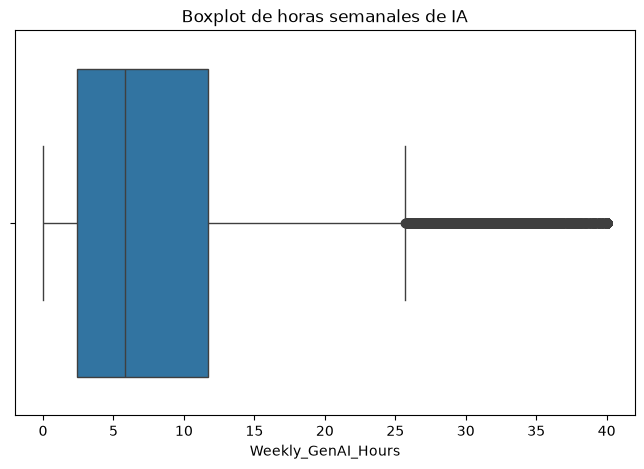

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Weekly_GenAI_Hours")
plt.title("Boxplot de horas semanales de IA")
plt.show()

In [ ]:
Q1 = df["Weekly_GenAI_Hours"].quantile(0.25)
Q3 = df["Weekly_GenAI_Hours"].quantile(0.75)
IQR = Q3 - Q1

lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

outliers = df[(df["Weekly_GenAI_Hours"] < lower_bound) | (df["Weekly_GenAI_Hours"] > upper_bound)]

print("Límite inferior:", lower_bound)
print("Límite superior:", upper_bound)
print("Cantidad de outliers:", len(outliers))
print("Porcentaje:", round(len(outliers) / len(df) * 100, 1), "%")

Límite inferior: -11.605
Límite superior: 25.715000000000003
Cantidad de outliers: 2583
Porcentaje: 5.2 %


#Hay 2583 estudiantes que usan la IA mas de 15H / semana, son los usuarios intensivos de la IA que necesitamos para la hipótesis 1, por eso conservamos estos datos.

#### EDA

Histograma 1: horas semanales de uso de IA

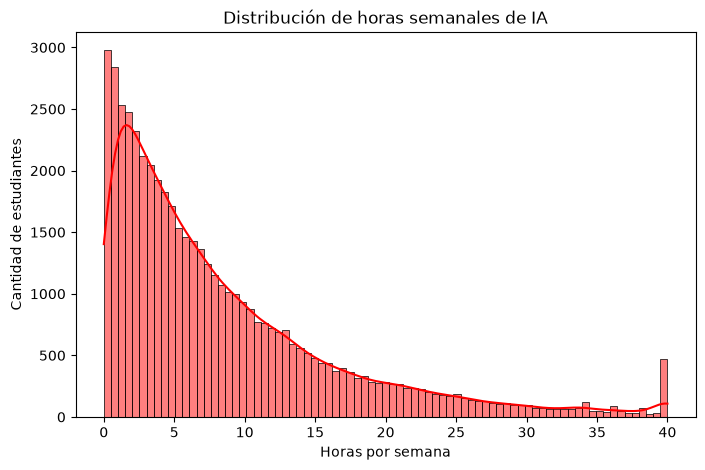

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Weekly_GenAI_Hours", kde=True, color="red", edgecolor="black")
plt.title("Distribución de horas semanales de IA")
plt.xlabel("Horas por semana")
plt.ylabel("Cantidad de estudiantes")
plt.show()

distribucion de cola a la derecha, la mayoría de estudiantes una la IA entre 5 y 10 horas y pocos llegan a 30 o 40 horas, por eso la media es 8.4 es mayor que la mediana 5.8

Histograma 2: Horas de estudio tradionales

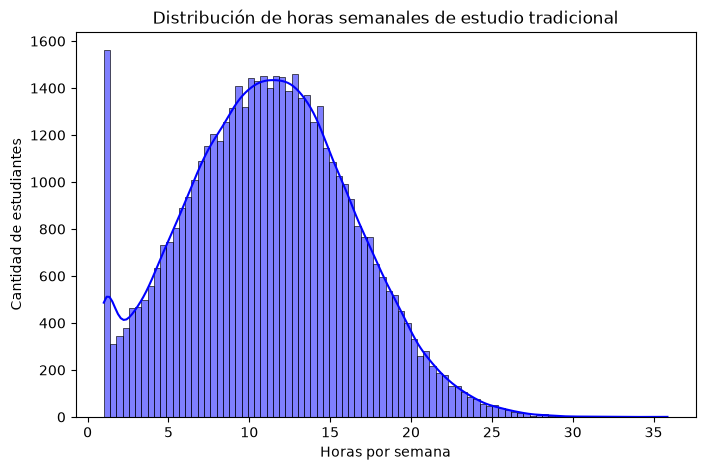

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="Traditional_Study_Hours", kde=True, color="blue", edgecolor="black")
plt.title("Distribución de horas semanales de estudio tradicional")
plt.xlabel("Horas por semana")
plt.ylabel("Cantidad de estudiantes")
plt.show()

Forma de campana casi simétrica, centrada en 11 h por semana (media ≈ mediana).
A diferencia de las horas de IA, aquí no hay una cola larga.
La barra aislada en 1 h son 1269 estudiantes con el valor mínimo exacto: el dataset tiene un piso en 1 hora.

Historgrama 3: Cambio de GPA

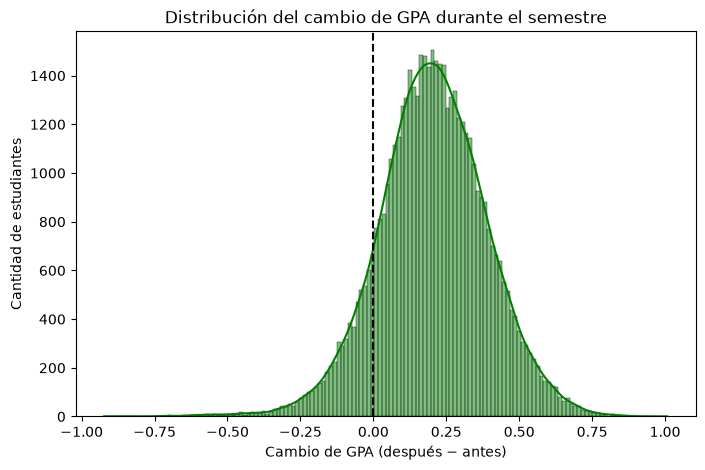

In [ ]:
plt.figure(figsize=(8,5))
sns.histplot(data=df, x="GPA_Change", kde=True, color="green", edgecolor="black")
plt.axvline(0, color="black", linestyle="--")
plt.title("Distribución del cambio de GPA durante el semestre")
plt.xlabel("Cambio de GPA (después − antes)")
plt.ylabel("Cantidad de estudiantes")
plt.show()

axvline la línea central explica que: todo lo que está a la derecha del cero, son estudiantes que mejoraron su promedio (GPA) con una subida atípica de +0.2 puntos.
A la izquierda notamos una minoría que empeoró durante el semestre.

#### Retención según el uso principal de la IA (hipótesis 3)

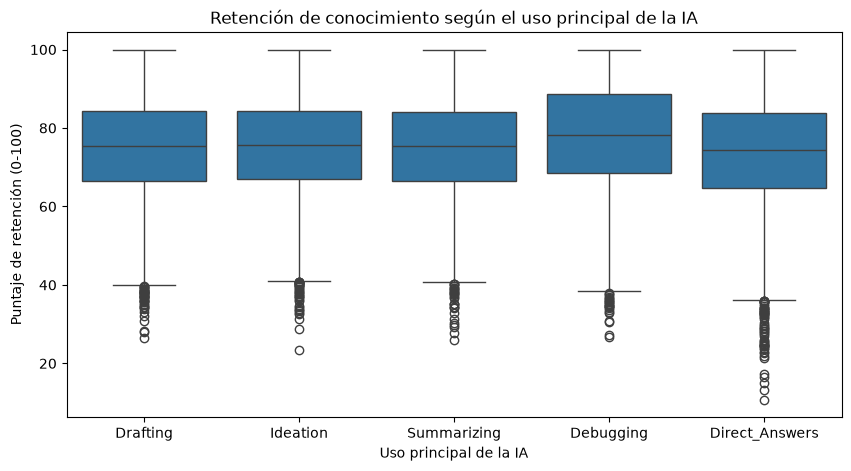

In [ ]:
plt.figure(figsize=(10,5))
sns.boxplot(data=df, x="Primary_Use_Case", y="Skill_Retention_Score")
plt.title("Retención de conocimiento según el uso principal de la IA")
plt.xlabel("Uso principal de la IA")
plt.ylabel("Puntaje de retención (0-100)")
plt.show()

In [ ]:
df.groupby("Primary_Use_Case")["Skill_Retention_Score"].mean().sort_values() # retención promedio por uso

Primary_Use_Case
Direct_Answers    73.718877
Summarizing       75.225024
Drafting          75.231097
Ideation          75.520224
Debugging         78.068964
Name: Skill_Retention_Score, dtype: float64

La hipótesis 3 se cumple, quienes piden respuestas directas retienen menos (73.7) y quienes depuran (debugging) retienen más (78.1)
La diferencia es moderada (4.4)  y las cajas de los boxplots se superponen, el uso influye, pero no lo explica todo.

Horas de Ia según la política de la universidad (H5)

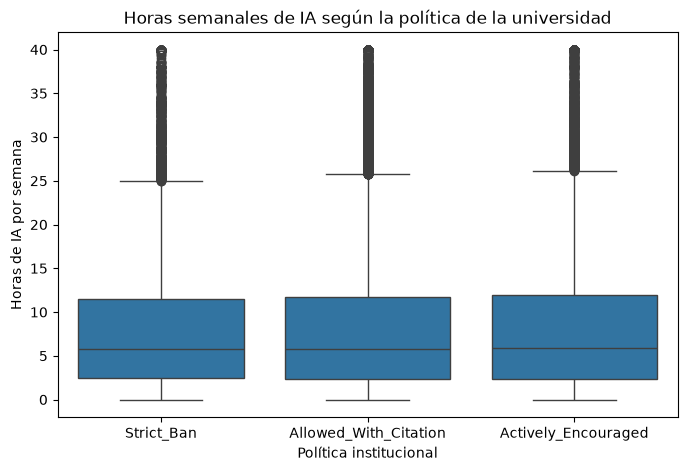

In [ ]:
plt.figure(figsize=(8,5))
sns.boxplot(data=df, x="Institutional_Policy", y="Weekly_GenAI_Hours",
            order=["Strict_Ban", "Allowed_With_Citation", "Actively_Encouraged"])
plt.title("Horas semanales de IA según la política de la universidad")
plt.xlabel("Política institucional")
plt.ylabel("Horas de IA por semana")
plt.show()

In [ ]:
df.groupby("Institutional_Policy")["Weekly_GenAI_Hours"].median() # mediana de horas de IA por política

Institutional_Policy
Actively_Encouraged      5.855
Allowed_With_Citation    5.740
Strict_Ban               5.830
Name: Weekly_GenAI_Hours, dtype: float64

H5 se cumple: la mediana de uso es casi igual en las tres políticas (5.7 a 5.9 h por semana). # prohibir la IA no reduce su uso: los estudiantes la usan igual, esté prohibida o fomentada

horas de estudio vs cambio de GPA (hipótesis H2)

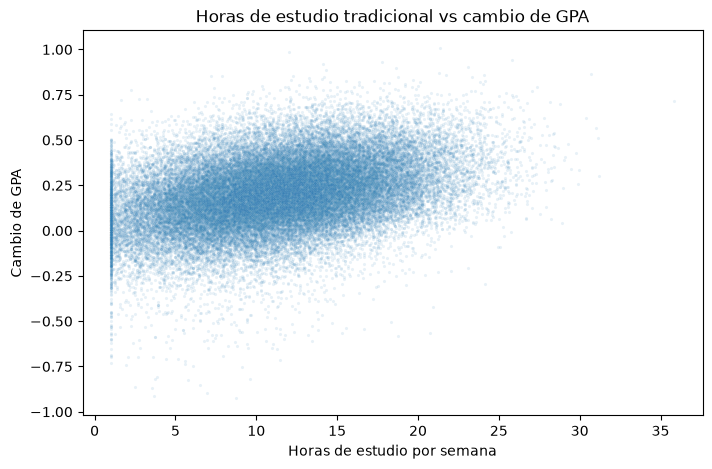

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Traditional_Study_Hours", y="GPA_Change", alpha=0.1, s=5)
plt.title("Horas de estudio tradicional vs cambio de GPA")
plt.xlabel("Horas de estudio por semana")
plt.ylabel("Cambio de GPA")
plt.show()

la nube sube a más horas de estudio tradicional, mayor mejora del GPA (relación positiva).
la nube es ancha, el estudio influye, pero no explica toda la mejora

horas de IA vs cambio de GPA

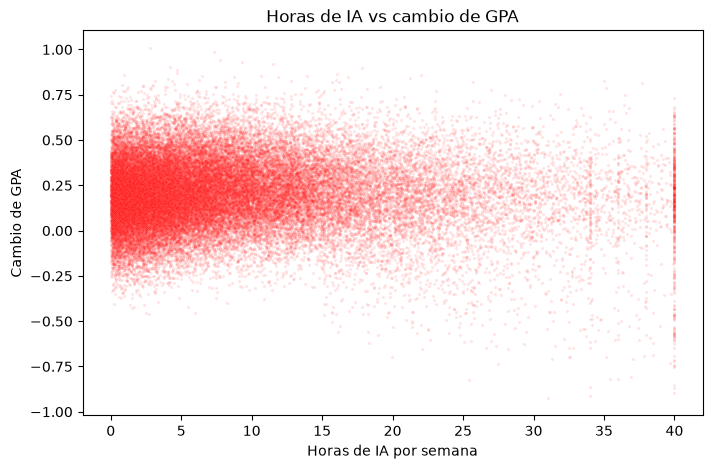

In [ ]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df, x="Weekly_GenAI_Hours", y="GPA_Change", alpha=0.1, s=5, color="red")
plt.title("Horas de IA vs cambio de GPA")
plt.xlabel("Horas de IA por semana")
plt.ylabel("Cambio de GPA")
plt.show()

In [ ]:
print("Estudio vs cambio de GPA:", round(df["Traditional_Study_Hours"].corr(df["GPA_Change"]), 2))
print("IA vs cambio de GPA:", round(df["Weekly_GenAI_Hours"].corr(df["GPA_Change"]), 2))

Estudio vs cambio de GPA: 0.38
IA vs cambio de GPA: -0.05


H2 se cumple: el estudio tradicional tiene correlación moderada con la mejora del promedio (GPA) 0.38,
mientras que las horas de IA no tienen relación (-0.05). Usar más IA no mejora las notas; estudiar sí.

Torta del riesgo de burnout

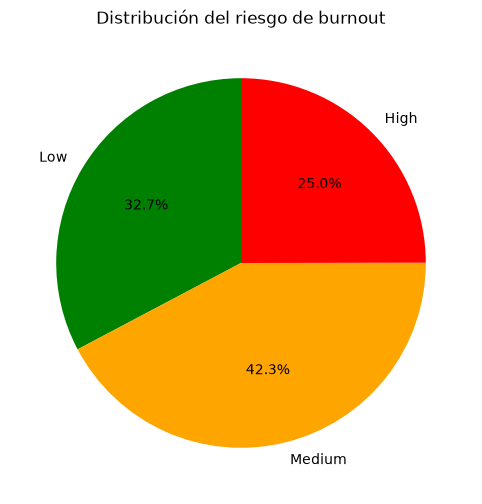

In [ ]:
plt.figure(figsize=(8,6))
conteo_burnout = df.Burnout_Risk_Level.value_counts().sort_index()
plt.pie(conteo_burnout, labels=conteo_burnout.index, autopct="%1.1f%%", startangle=90,
        colors=["green", "orange", "red"])
plt.title("Distribución del riesgo de burnout")
plt.show()

el 25% de estudiantes tiene riesgo ALTO de burnout; la mayoría (42%) tiene riesgo medio

# Burnout según nivel de usi de la IA (H1)

Agrupamos las horas en niveles de uso

In [ ]:
df["AI_Usage_Level"] = pd.cut(
    df["Weekly_GenAI_Hours"],
    bins=[-1, 5, 15, 40],
    labels=["Bajo (0-5 h)", "Medio (5-15 h)", "Alto (15-40 h)"]
)

df.AI_Usage_Level.value_counts().sort_index() # cuántos estudiantes hay en cada nivel de uso

AI_Usage_Level
Bajo (0-5 h)      22592
Medio (5-15 h)    18874
Alto (15-40 h)     8534
Name: count, dtype: int64

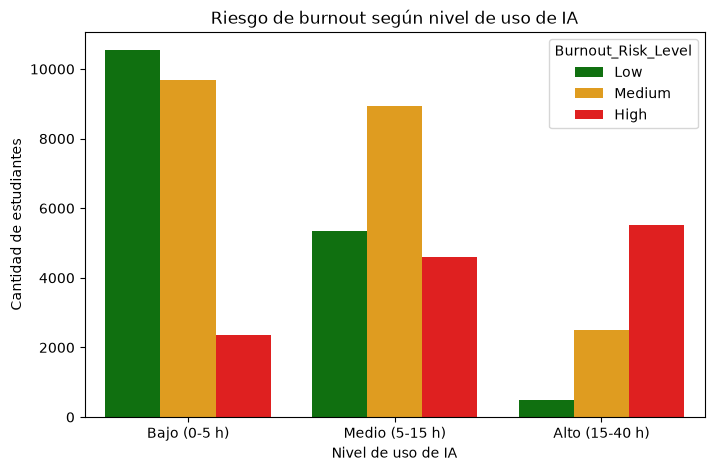

In [ ]:
plt.figure(figsize=(8,5))
sns.countplot(data=df, x="AI_Usage_Level", hue="Burnout_Risk_Level",
              palette=["green", "orange", "red"])
plt.title("Riesgo de burnout según nivel de uso de IA")
plt.xlabel("Nivel de uso de IA")
plt.ylabel("Cantidad de estudiantes")
plt.show()

EL grupo alto tiene menos estudiantes que el bajo. Lo veremos en procentajes

In [ ]:
pd.crosstab(df["AI_Usage_Level"], df["Burnout_Risk_Level"], normalize="index") * 100 # % de burnout dentro de cada nivel de uso

Burnout_Risk_Level,Low,Medium,High
AI_Usage_Level,,,
Bajo (0-5 h),46.635977,42.886863,10.477160
Medio (5-15 h),28.298188,47.372046,24.329766
Alto (15-40 h),5.765175,29.458636,64.776189


La H1 se cumple el riesgo de burnout pasa de 10.5% que es el uso bajo al 64.8% que es el uso más alto.
Esta asociación, no prueba una causa, pero puede que el agotamiento lleve a usar más IA.

# Retención según habilidad con prompt (H4)

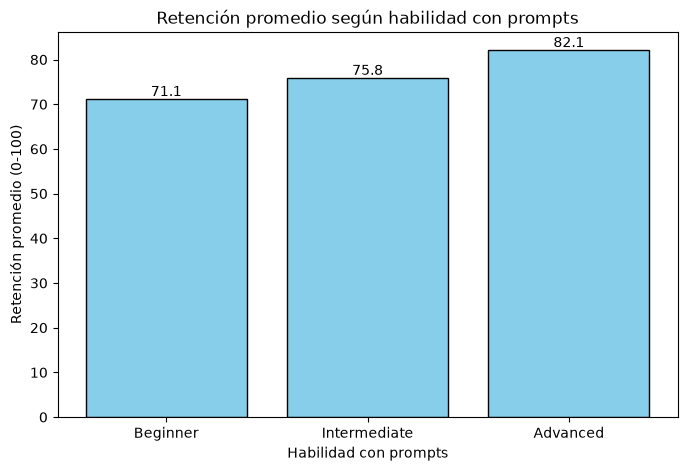

In [ ]:
retencion_skill = df.groupby("Prompt_Engineering_Skill", observed=True)["Skill_Retention_Score"].mean()

plt.figure(figsize=(8,5))
barras = plt.bar(retencion_skill.index, retencion_skill.values, color="skyblue", edgecolor="black")
plt.bar_label(barras, fmt="%.1f")
plt.title("Retención promedio según habilidad con prompts")
plt.xlabel("Habilidad con prompts")
plt.ylabel("Retención promedio (0-100)")
plt.show()

In [ ]:
df.groupby("Prompt_Engineering_Skill", observed=True)["Weekly_GenAI_Hours"].median() # horas de IA por nivel de habilidad

Prompt_Engineering_Skill
Beginner        5.76
Intermediate    5.73
Advanced        5.95
Name: Weekly_GenAI_Hours, dtype: float64

H4 se cumple: los avanzados retienen 11 puntos más que los principiantes (82.1 vs 71.1),
usando casi las mismas horas de IA (~5.8 h). Importa cómo se usa la IA, no cuánto

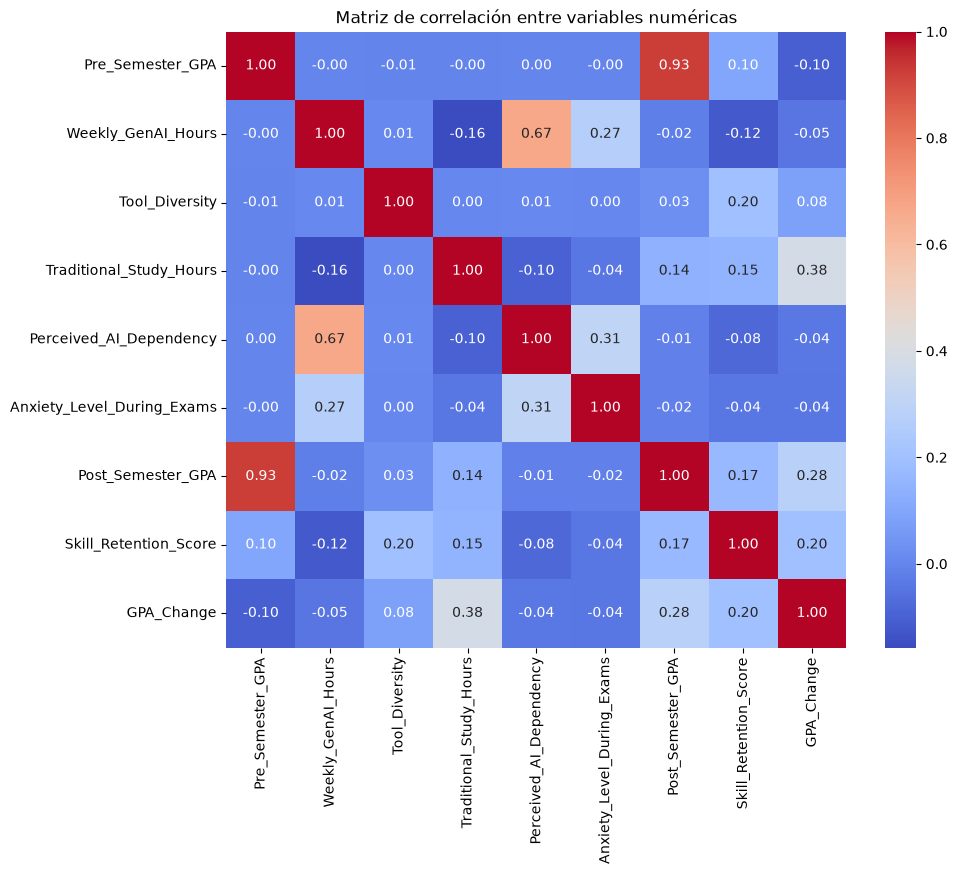

In [ ]:
df_corr = df.select_dtypes(include="number").drop(columns=["Student_ID"])

plt.figure(figsize=(10,8))
sns.heatmap(df_corr.corr(), annot=True, cmap="coolwarm", fmt=".2f")
plt.title("Matriz de correlación entre variables numéricas")
plt.show()

La correlación más fuerte es horas de IA vs dependencia percibida (0.67): quien más la usa, siente más dependencia.
La ansiedad en exámenes también sube con la dependencia (0.31) y con las horas de IA (0.27).
Comentario: La dependencia y la ansiedad son escalas discretas del 1 al 10, que el estudiante se autoasigna, así que se interpretan como tendencia.

#### Prueba de normalidad

In [ ]:
"""
H0: la variable es normal
H1: la variable no es normal

si p-value > 0.05 -> no rechazamos H0, "podría ser normal"
si p-value < 0.05 -> rechazamos H0, NO ES NORMAL
"""

'\nH0: la variable es normal\nH1: la variable no es normal\n\nsi p-value > 0.05 -> no rechazamos H0, "podría ser normal"\nsi p-value < 0.05 -> rechazamos H0, NO ES NORMAL\n'

Horas de estudio

In [ ]:
data = df["Traditional_Study_Hours"]
data_std = (data - data.mean()) / data.std() # se estandariza la variable antes de la prueba

stat, p_value = kstest(data_std, "norm")
print("Estadístico:", round(stat, 3))
print("p-value:", p_value)

Estadístico: 0.024
p-value: 3.746130036474806e-25


Horas de IA

In [ ]:
data = df["Weekly_GenAI_Hours"]
data_std = (data - data.mean()) / data.std()

stat, p_value = kstest(data_std, "norm")
print("Estadístico:", round(stat, 3))
print("p-value:", p_value)

Estadístico: 0.154
p-value: 0.0


Ambas variables rechazan H0 (p-value < 0.05), pero con 50000 datos la prueba es muy estricta y rechaza casi todo.
Estudio: estadístico 0.024 (desvío mínimo) y forma de campana en el histograma -> aproximadamente normal.
IA: estadístico 0.154 (6 veces más lejos) por su cola larga a la derecha -> claramente NO es normal

#### Conclusiones


# Resultado de las hipótesis

H1: A más horas de IA, mayor riesgo de burnout 
El riesgo alto pasa de 10.5% (uso bajo) a 64.8% (uso alto) 
Es el resultado más fuerte del análisis. Entre los estudiantes que usan poca IA, solo el 10% tiene riesgo alto de burnout. Entre los que la usan más de 15 horas por semana, el riesgo alto sube al 65%. Además, quienes más la usan se sienten más dependientes de ella y más ansiosos en los exámenes.

H2: El estudio tradicional explica la mejora del GPA mejor que la IA 
Las horas de estudio tienen una relación moderada con la mejora del GPA (0.38), mientras que las horas de IA prácticamente no tienen relación (−0.05). Usar más IA no hace que las notas suban.

H3: Pedir respuestas directas se asocia a menor retención 
Se cumple, pero la diferencia es pequeña. Quienes usan la IA para obtener respuestas directas retienen menos (73.7) que quienes la usan para depurar (78.1).

H4: Importa cómo se usa la IA, no cuánto
Los estudiantes con nivel avanzado en prompts retienen 11 puntos más que los principiantes, aunque todos usan la IA más o menos las mismas horas.

H5: Prohibir la IA no reduce su uso 
Los estudiantes usan la IA casi lo mismo en universidades que la prohíben y en las que la fomentan, alrededor de 6 horas por semana.


### Conclusión final
La IA no es buena ni mala en sí misma; lo que cambia los resultados es la forma de usarla. Cuando se usa para entender y resolver problemas, los estudiantes retienen más. Cuando se usa en exceso o para saltarse el esfuerzo, aparece más agotamiento y las notas no mejoran. Como prohibirla tampoco funciona, parece más útil enseñar a usarla bien.

### Limitaciones

Estos resultados muestran relaciones entre variables, pero no prueban que una cause la otra. Por ejemplo, puede que la IA no cause el burnout, sino que los estudiantes ya agotados la usen más. Además, la dependencia y la ansiedad son valores que cada estudiante se asignó a sí mismo, y algunas columnas tienen límites fijos (40 h de IA, 1 h de estudio, GPA máximo de 4.0) que pueden afectar algunas comparaciones.